# Step 4b and step 5 - Hybrid simulation and clinical analysis

* **Step 4b** (`scripts/12_evaluate_hybrid.py`): strategy C tunes the detectors on a hybrid simulation. Synthetic fast ripples are inserted into real background of the training patients, and their rate, share on spikes, frequency, duration and SNR are calibrated on those patients' markings. C is compared with A (tuned on real training patients) and B (fully synthetic simulator).
* **Step 5** (`scripts/13_clinical.py`): does the post-resection fast-ripple rate predict a poor surgical outcome (ILAE > 1)? Patient level, exploratory (22 patients, 8 not seizure-free).

In [1]:
import pandas as pd
from IPython.display import Image, display

from epidetect.config import load_config

cfg = load_config()
R, F = cfg["paths"]["results_dir"], cfg["paths"]["figures_dir"]
pd.set_option("display.width", 180)
def fmt(df, est="estimate", lo="ci_low", hi="ci_high"):
    return df.assign(value=df.apply(lambda r: f"{r[est]:.3f} [{r[lo]:.3f}, {r[hi]:.3f}]", axis=1))

## 1. Hybrid calibration per fold (without the test patient)

In [2]:
pd.read_csv(R / "hybrid_fold_calibration.csv", dtype={"left_out": str}).round(3)

,left_out,rate_per_min,p_on_spike,median_freq_hz,median_duration_ms,median_snr_db,n_markings
0,none (all patients),2.487,0.624,303.030,18.0,15.197,2378
1,01,3.043,0.668,302.326,18.5,15.447,2203
2,02,2.614,0.643,304.348,18.0,15.294,2308
3,03,2.563,0.626,303.030,18.0,15.214,2372
4,04,2.522,0.623,303.571,18.0,15.192,2315
5,05,2.628,0.594,303.030,18.0,15.147,2147
6,06,1.134,0.390,310.345,16.0,13.627,965
7,07,2.799,0.630,303.030,18.0,15.252,2356
8,08,2.323,0.691,300.000,18.5,15.515,2054
9,09,2.512,0.628,303.030,18.0,15.228,2365


Leaving out patient 06 changes the calibration a lot (rate and share on spikes): one patient dominates the dataset statistics.

## 2. Thresholds chosen in every fold

In [3]:
th = pd.read_csv(R / "strategy_thresholds.csv", dtype={"patient": str})
th.groupby("strategy")[["energy_k", "wavelet_z", "ml_threshold"]].describe().round(2).T

strategy                A      B      C
energy_k     count  19.00  19.00  19.00
             mean    7.95   3.47   7.00
             std     0.23   0.11   0.75
             min     7.00   3.00   6.00
             25%     8.00   3.50   6.50
             50%     8.00   3.50   7.00
             75%     8.00   3.50   7.50
             max     8.00   3.50   8.00
wavelet_z    count  19.00  19.00  19.00
             mean   12.79   6.00  12.32
             std     1.36   0.00   0.95
             min    12.00   6.00  12.00
             25%    12.00   6.00  12.00
             50%    12.00   6.00  12.00
             75%    13.50   6.00  12.00
             max    15.00   6.00  15.00
ml_threshold count  19.00  19.00  19.00
             mean    0.41   0.45   0.54
             std     0.02   0.07   0.05
             min     0.40   0.35   0.40
             25%     0.40   0.40   0.50
             50%     0.40   0.40   0.55
             75%     0.40   0.50   0.57
             max     0.45   0.60   0.60

## 3. A vs B vs C on the test patients

In [4]:
cmp = pd.read_csv(R / "strategy_comparison.csv")
main = fmt(cmp[cmp.analysis == "all channels"])
main.pivot_table(index=["detector", "comparison"], columns="metric", values="value", aggfunc="first")

metric              fp_per_min_no_fr_patients              macro_f1       macro_precision          macro_recall              micro_f1    paired_f1_difference
detector comparison                                                                                                                                          
energy   A               0.299 [0.000, 0.969]  0.194 [0.088, 0.318]  0.173 [0.079, 0.286]  0.281 [0.125, 0.452]  0.521 [0.185, 0.678]                     NaN
         B               0.688 [0.409, 1.777]  0.177 [0.107, 0.262]  0.108 [0.062, 0.167]  0.804 [0.676, 0.908]  0.270 [0.121, 0.446]                     NaN
         C               0.329 [0.000, 1.131]  0.196 [0.092, 0.319]  0.152 [0.069, 0.252]  0.326 [0.158, 0.510]  0.487 [0.207, 0.656]                     NaN
         C - A                            NaN                   NaN                   NaN                   NaN                   NaN   0.003 [-0.009, 0.021]
         C - B                            NaN                   NaN                   NaN                   NaN                   NaN   0.020 [-0.038, 0.078]
ml       A               0.000 [0.000, 0.000]  0.250 [0.124, 0.386]  0.354 [0.210, 0.499]  0.281 [0.138, 0.437]  0.609 [0.370, 0.714]                     NaN
         B               1.554 [0.545, 1.906]  0.136 [0.080, 0.208]  0.086 [0.046, 0.140]  0.631 [0.474, 0.772]  0.220 [0.097, 0.363]                     NaN
         C               0.000 [0.000, 0.000]  0.109 [0.035, 0.214]  0.205 [0.099, 0.327]  0.094 [0.024, 0.200]  0.100 [0.017, 0.232]                     NaN
         C - A                            NaN                   NaN                   NaN                   NaN                   NaN  -0.141 [-0.307, 0.033]
         C - B                            NaN                   NaN                   NaN                   NaN                   NaN  -0.027 [-0.134, 0.098]
wavelet  A               0.060 [0.000, 0.162]  0.115 [0.055, 0.185]  0.147 [0.069, 0.242]  0.123 [0.057, 0.199]  0.303 [0.159, 0.350]                     NaN
         B               1.524 [0.273, 3.231]  0.088 [0.047, 0.141]  0.055 [0.027, 0.092]  0.548 [0.400, 0.689]  0.110 [0.044, 0.185]                     NaN
         C               0.060 [0.000, 0.162]  0.118 [0.058, 0.189]  0.142 [0.064, 0.241]  0.141 [0.065, 0.229]  0.297 [0.179, 0.340]                     NaN
         C - A                            NaN                   NaN                   NaN                   NaN                   NaN   0.003 [-0.001, 0.009]
         C - B                            NaN                   NaN                   NaN                   NaN                   NaN   0.030 [-0.038, 0.096]

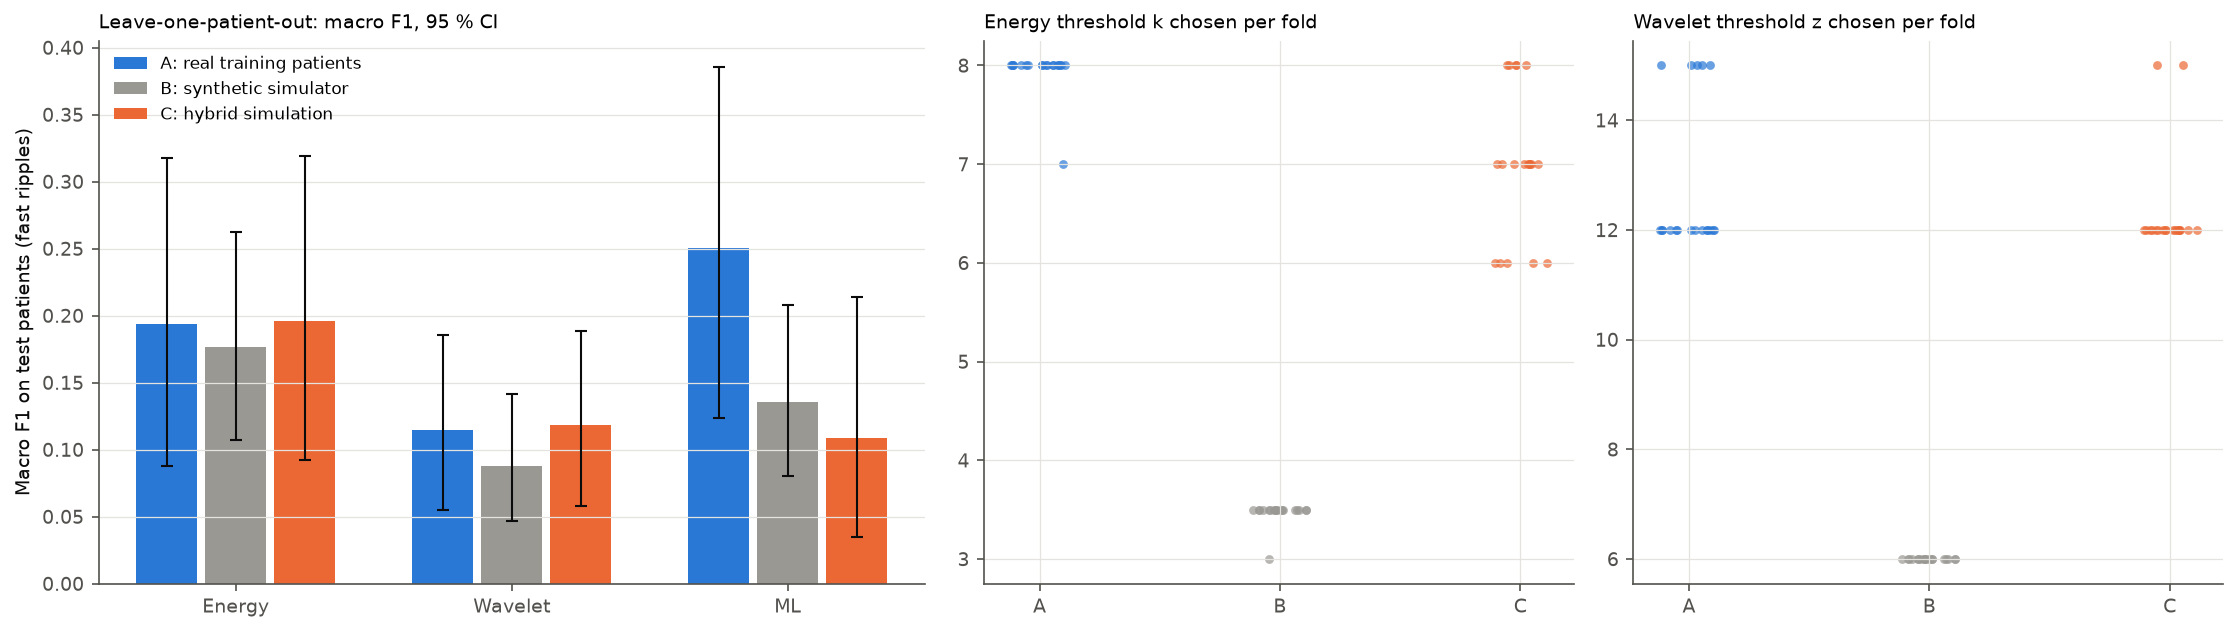

In [5]:
display(Image(filename=str(F / "strategy_comparison.png")))

* For the **threshold-based** detectors (energy, wavelet), the hybrid simulation sets the thresholds almost where real data would (k ~ 7 vs 8, z = 12 vs 12) and matches strategy A in macro F1. The gain over B is positive but its CI includes 0.
* The **ML** detector trained on hybrid data fails (macro recall 0.09). Plausible, untested explanation: a threshold only needs realistic noise, but a classifier also needs realistic positives; inserted Hann-windowed sinusoids are cleaner than real FRs, and unmarked real FRs in the background are learned as negatives.

## 4. Clinical analysis: post-resection FR rate vs outcome

In [6]:
patients = pd.read_csv(R / "clinical_patients.csv", dtype={"patient": str})
patients[patients.analysis == "all channels"][["patient", "ilae", "not_seizure_free", "n_channels",
    "channel_minutes", "n_reference", "n_energy", "n_wavelet", "n_ml"]].round(1)

,patient,ilae,not_seizure_free,n_channels,channel_minutes,n_reference,n_energy,n_wavelet,n_ml
0,01,1,False,15,42.0,0,3,0,0
1,02,1,False,22,254.1,4,20865,1832,46
2,03,1,False,10,33.3,1,18,3,1
3,04,1,False,17,65.2,0,1,0,3
4,05,1,False,19,42.1,0,8,3,1
5,06,3,True,23,78.6,22,166,72,2
6,07,1,False,20,117.7,4,143,24,0
7,08,1,False,11,37.4,1,13,0,0
8,09,1,False,3,37.4,0,29,12,1
9,10,3,True,5,16.1,2,10,24,0


In [7]:
auc = pd.read_csv(R / "clinical_auc.csv")
fmt(auc, "auc")[["analysis", "score", "value", "p_permutation", "n_not_seizure_free", "n_seizure_free"]]

,analysis,score,value,p_permutation,n_not_seizure_free,n_seizure_free
0,all channels,reference,"0.830 [0.621, 1.000]",0.0039,8,14
1,all channels,energy,"0.446 [0.210, 0.696]",0.7010,8,14
2,all channels,wavelet,"0.612 [0.362, 0.839]",0.4114,8,14
3,all channels,ml,"0.402 [0.179, 0.638]",0.4545,8,14
4,QC-clean channels,reference,"0.839 [0.643, 1.000]",0.0015,8,14
5,QC-clean channels,energy,"0.491 [0.250, 0.741]",0.9739,8,14
6,QC-clean channels,wavelet,"0.625 [0.384, 0.848]",0.3630,8,14
7,QC-clean channels,ml,"0.402 [0.179, 0.638]",0.4346,8,14


In [8]:
rule = pd.read_csv(R / "clinical_rule.csv").iloc[0]
pd.DataFrame({m: [f"{rule[m]:.2f} [{rule[m + '_low']:.2f}, {rule[m + '_high']:.2f}]", int(rule[m + '_n'])]
              for m in ["sensitivity", "specificity", "ppv", "npv"]}, index=["value [95 % Wilson CI]", "n"])

,sensitivity,specificity,ppv,npv
value [95 % Wilson CI],"0.75 [0.41, 0.93]","0.71 [0.45, 0.88]","0.60 [0.31, 0.83]","0.83 [0.55, 0.95]"
n,8,14,10,12


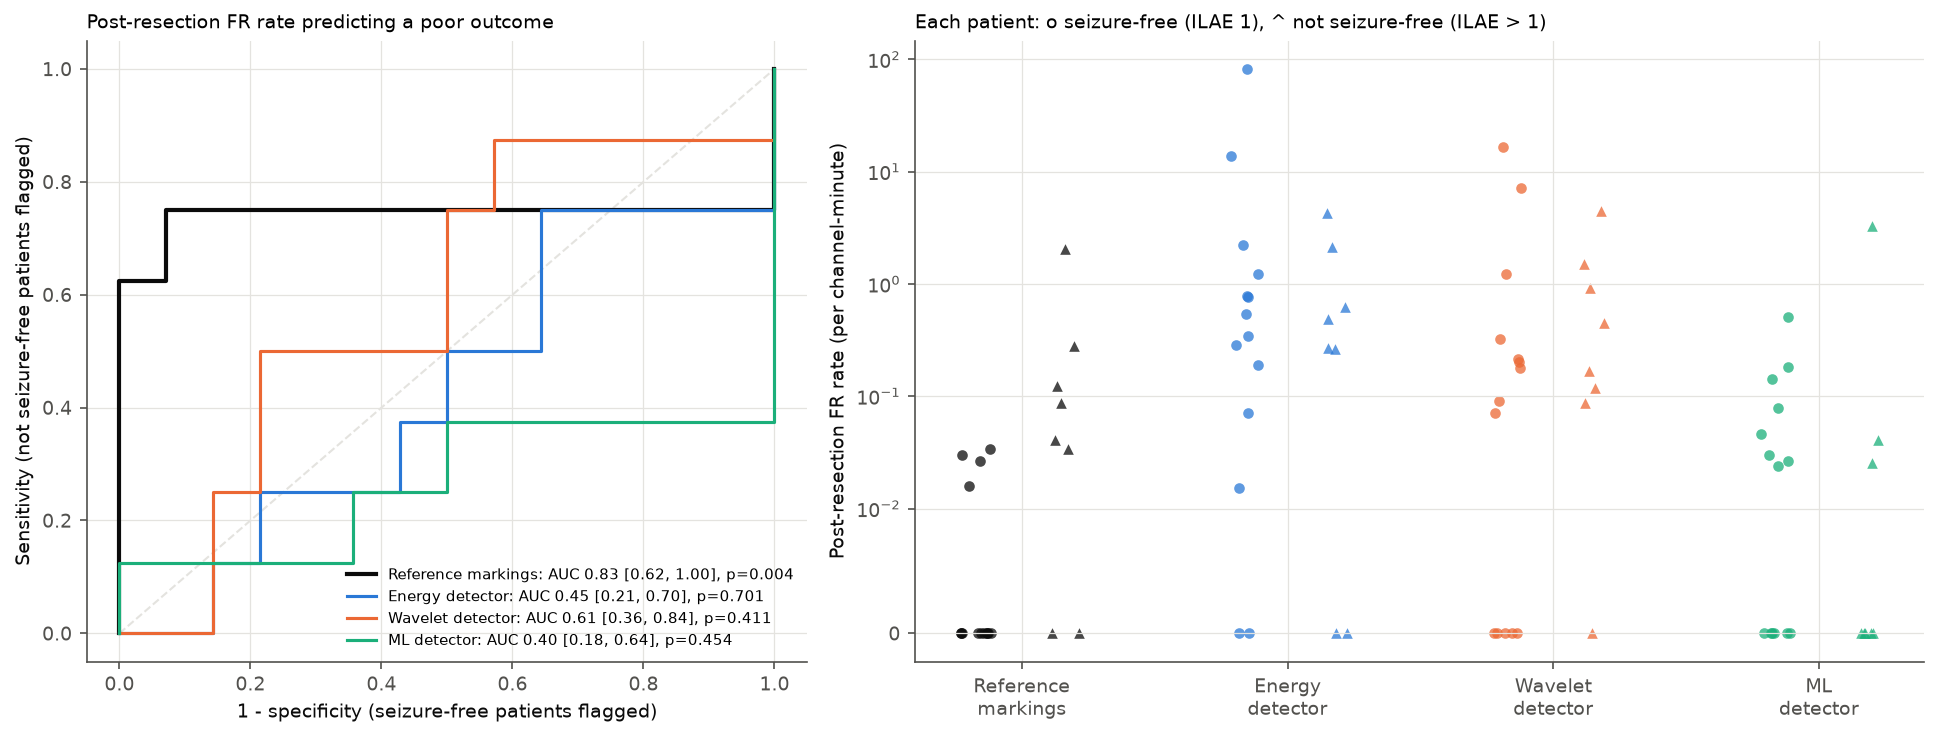

In [9]:
display(Image(filename=str(F / "clinical_roc.png")))

## 5. Take-aways

* With the **reference markings**, the post-resection FR rate separates patients who stay seizure-free from the others: AUC 0.83 [0.62, 1.00], permutation p = 0.004. The rule 'at least one FR after resection' has sensitivity 6/8 and specificity 10/14. This reproduces, on the public data, the finding of the original publication.
* With **our detectors**, post-resection rates do not predict the outcome (AUC 0.40-0.61, CIs include 0.5): their false positives in seizure-free patients (e.g. thousands of energy detections in patient 02) drown the signal. A detector with macro F1 ~ 0.2 against the reference is not clinically usable as is.
* 22 patients, 8 events: exploratory. Several CIs are wide and the upper bound reaches 1.
* The channel-level analysis (FR rate vs resected channels) is implemented but skipped: no channel-level resection labels exist for this dataset.